# Use Case Selection Example

## Setup

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# Reproducibility
rng = np.random.default_rng(42)

# Image parameters
IMAGE_SIZE = 64
MIN_CIRCLES = 1
MAX_CIRCLES = 10
MIN_RADIUS = 3
MAX_RADIUS = 6

# Dataset parameters
N_TRAIN = 3000
N_VAL = 500
N_TEST = 500

## Data Generator


In [ ]:
def generate_image(
    rng,
    image_size=IMAGE_SIZE,
    min_circles=MIN_CIRCLES,
    max_circles=MAX_CIRCLES,
    min_radius=MIN_RADIUS,
    max_radius=MAX_RADIUS,
):
    """Generate a grayscale image containing non-overlapping circles."""

    image = np.zeros((image_size, image_size), dtype=np.float32)
    n_circles = int(rng.integers(min_circles, max_circles + 1))

    circles = []
    yy, xx = np.ogrid[:image_size, :image_size]

    for _ in range(n_circles):
        for _ in range(1000):  # Maximum placement attempts
            radius = int(rng.integers(min_radius, max_radius + 1))
            x = int(rng.integers(radius, image_size - radius))
            y = int(rng.integers(radius, image_size - radius))

            # Require separation between circles
            if all(
                np.hypot(x - cx, y - cy) > radius + cr + 2
                for cx, cy, cr in circles
            ):
                mask = (xx - x) ** 2 + (yy - y) ** 2 <= radius**2
                image[mask] = 1.0
                circles.append((x, y, radius))
                break
        else:
            raise RuntimeError("Unable to place all circles.")

    return image, n_circles

## Generate Dataset

In [ ]:
def generate_dataset(n_samples, rng):
    """Generate a dataset of images and object counts."""

    images = np.zeros((n_samples, IMAGE_SIZE, IMAGE_SIZE), dtype=np.float32)
    labels = np.zeros(n_samples, dtype=np.int64)

    for i in range(n_samples):
        images[i], labels[i] = generate_image(rng)

    return images, labels


X_train, y_train = generate_dataset(N_TRAIN, rng)
X_val, y_val = generate_dataset(N_VAL, rng)
X_test, y_test = generate_dataset(N_TEST, rng)

print(f"Training:   {X_train.shape}, {y_train.shape}")
print(f"Validation: {X_val.shape}, {y_val.shape}")
print(f"Test:       {X_test.shape}, {y_test.shape}")

Training:   (3000, 64, 64), (3000,)
Validation: (500, 64, 64), (500,)
Test:       (500, 64, 64), (500,)


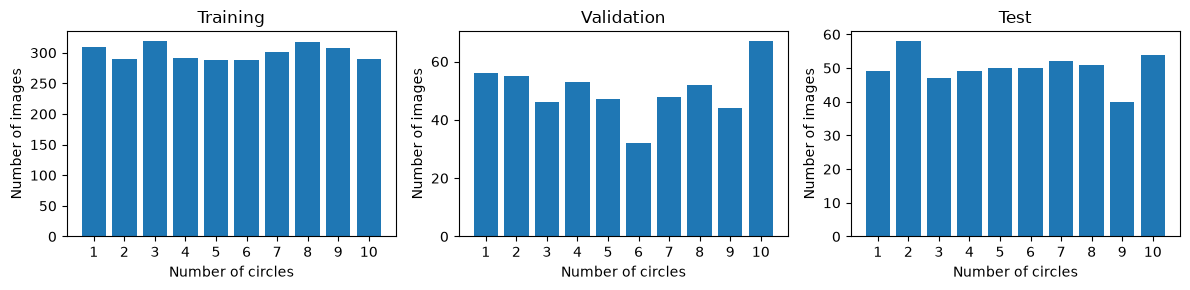

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3))

for ax, labels, title in zip(
    axes,
    [y_train, y_val, y_test],
    ["Training", "Validation", "Test"],
):
    counts = np.bincount(labels, minlength=MAX_CIRCLES + 1)[MIN_CIRCLES:]

    ax.bar(range(MIN_CIRCLES, MAX_CIRCLES + 1), counts)
    ax.set_title(title)
    ax.set_xlabel("Number of circles")
    ax.set_ylabel("Number of images")
    ax.set_xticks(range(MIN_CIRCLES, MAX_CIRCLES + 1))

plt.tight_layout()
plt.show()

## Evaluation Metrics

$$
\mathrm{Acc} = \frac{1}{N} \sum_{i=1}^{N} \mathbf{1}(\hat{y}_i = y_i)
$$

$$
\mathrm{MAE} = \frac{1}{N} \sum_{i=1}^{N} |\hat{y}_i - y_i|
$$

In [5]:
def evaluate_counts(y_true, y_pred):
    """Evaluate object-count predictions."""

    accuracy = np.mean(y_true == y_pred)
    mae = np.mean(np.abs(y_true - y_pred))

    return {"accuracy": accuracy, "mae": mae}

## ML Evaluation

### Setup

In [ ]:
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(42)

# Use a GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


def make_loader(images, labels, batch_size=64, shuffle=False):
    X = torch.from_numpy(images).unsqueeze(1)
    y = torch.from_numpy(labels - MIN_CIRCLES)

    dataset = TensorDataset(X, y)
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle)


train_loader = make_loader(X_train, y_train, shuffle=True)
val_loader = make_loader(X_val, y_val)
test_loader = make_loader(X_test, y_test)

Using device: cpu


### Model Setup

In [ ]:
class CircleCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(64, MAX_CIRCLES - MIN_CIRCLES + 1),
        )

    def forward(self, x):
        return self.network(x)


model = CircleCNN().to(device)

print(model)
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters()):,}")

CircleCNN(
  (network): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): AdaptiveAvgPool2d(output_size=1)
    (9): Flatten(start_dim=1, end_dim=-1)
    (10): Linear(in_features=64, out_features=10, bias=True)
  )
)
Trainable parameters: 23,946


### Training

In [8]:
import time

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

N_EPOCHS = 15

train_losses = []
val_losses = []

start = time.perf_counter()

for epoch in range(N_EPOCHS):
    # Training
    model.train()
    running_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

    train_loss = running_loss / len(train_loader.dataset)

    # Validation
    model.eval()
    running_loss = 0.0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

    val_loss = running_loss / len(val_loader.dataset)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(
        f"Epoch {epoch + 1:2d}/{N_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

if device.type == "cuda":
    torch.cuda.synchronize()

training_time = time.perf_counter() - start

print(f"\nTraining time: {training_time:.2f} seconds")

Epoch  1/15 | Train Loss: 2.2231 | Val Loss: 2.1284
Epoch  2/15 | Train Loss: 1.9075 | Val Loss: 1.5796
Epoch  3/15 | Train Loss: 1.3643 | Val Loss: 1.1832
Epoch  4/15 | Train Loss: 1.1526 | Val Loss: 1.1163
Epoch  5/15 | Train Loss: 1.0639 | Val Loss: 1.0127
Epoch  6/15 | Train Loss: 1.0176 | Val Loss: 0.9841
Epoch  7/15 | Train Loss: 0.9889 | Val Loss: 0.9997
Epoch  8/15 | Train Loss: 0.9710 | Val Loss: 0.9326
Epoch  9/15 | Train Loss: 0.9378 | Val Loss: 0.9168
Epoch 10/15 | Train Loss: 0.9266 | Val Loss: 0.9109
Epoch 11/15 | Train Loss: 0.8994 | Val Loss: 0.8811
Epoch 12/15 | Train Loss: 0.8772 | Val Loss: 0.8772
Epoch 13/15 | Train Loss: 0.8690 | Val Loss: 0.8584
Epoch 14/15 | Train Loss: 0.8478 | Val Loss: 0.8319
Epoch 15/15 | Train Loss: 0.8330 | Val Loss: 0.8333

Training time: 54.00 seconds


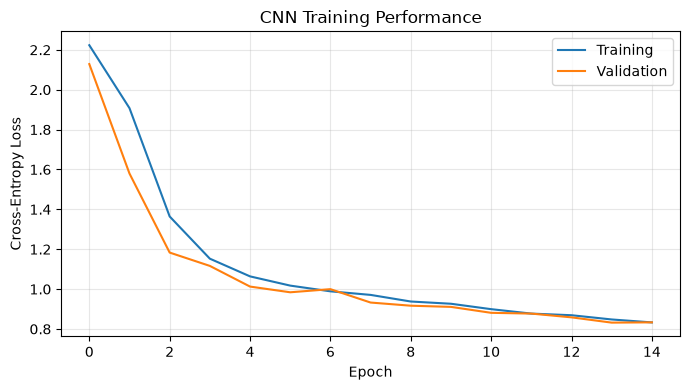

In [9]:
plt.figure(figsize=(7, 4))

plt.plot(train_losses, label="Training")
plt.plot(val_losses, label="Validation")

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("CNN Training Performance")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Evaluation

In [10]:
def predict_cnn(model, loader):
    """Return predicted object counts and ground-truth labels."""

    model.eval()

    predictions = []
    targets = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)

            outputs = model(images)
            predicted = outputs.argmax(dim=1)

            predictions.append(predicted.cpu().numpy() + MIN_CIRCLES)
            targets.append(labels.numpy() + MIN_CIRCLES)

    return np.concatenate(predictions), np.concatenate(targets)


y_pred_cnn, y_true = predict_cnn(model, test_loader)

cnn_metrics = evaluate_counts(y_true, y_pred_cnn)

print(f"Test accuracy: {cnn_metrics['accuracy']:.2%}")
print(f"Test MAE:      {cnn_metrics['mae']:.3f}")

Test accuracy: 62.00%
Test MAE:      0.424


### Visualize Predictions

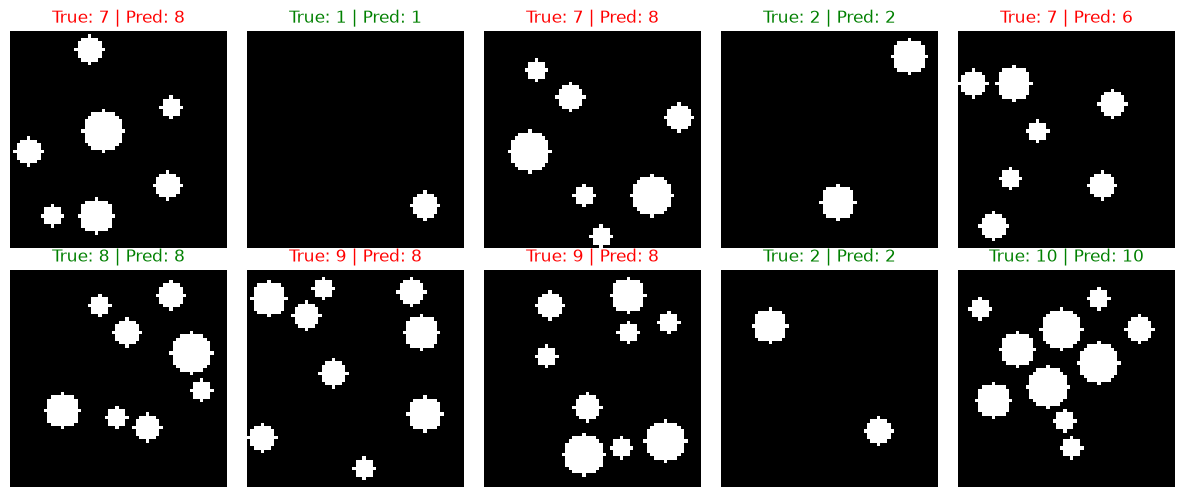

In [11]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for ax, i in zip(axes.flat, range(10)):
    ax.imshow(X_test[i], cmap="gray", vmin=0, vmax=1)

    correct = y_pred_cnn[i] == y_test[i]

    ax.set_title(
        f"True: {y_test[i]} | Pred: {y_pred_cnn[i]}",
        color="green" if correct else "red",
    )
    ax.axis("off")

plt.tight_layout()
plt.show()